# Ánh xạ dữ liệu không tách được tuyến tính sang không gian 3 chiều (mục 7.1.3)

phi(x1, x2) = (x1, x2, x1^2 + x2^2)

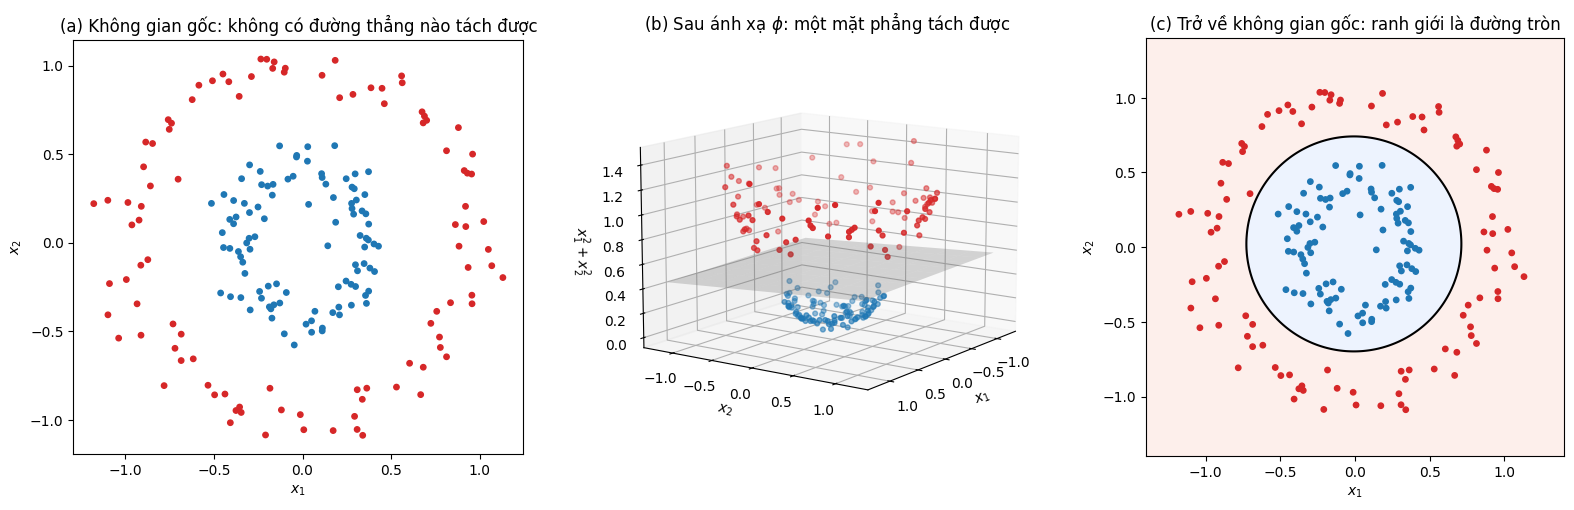

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

X, y = make_circles(n_samples=200, factor=0.4, noise=0.08, random_state=0)
Z = np.column_stack([X, X[:, 0]**2 + X[:, 1]**2])     # phi(x)
svm = SVC(kernel='linear', C=1).fit(Z, y)
w, b = svm.coef_[0], svm.intercept_[0]
colors = np.array(['#D62728', '#1F77B4'])[y]

fig = plt.figure(figsize=(16, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax1.scatter(X[:, 0], X[:, 1], c=colors, s=15)
ax1.set_aspect('equal'); ax1.set_xlabel('$x_1$'); ax1.set_ylabel('$x_2$')
ax1.set_title('(a) Không gian gốc: không có đường thẳng nào tách được')

ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax2.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=colors, s=12)
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 10), np.linspace(-1.2, 1.2, 10))
g3 = -(w[0] * g1 + w[1] * g2 + b) / w[2]              # mặt phẳng w^T z + b = 0
ax2.plot_surface(g1, g2, g3, alpha=0.25, color='gray')
ax2.set_xlabel('$x_1$'); ax2.set_ylabel('$x_2$'); ax2.set_zlabel('$x_1^2 + x_2^2$')
ax2.view_init(elev=12, azim=35)
ax2.set_title('(b) Sau ánh xạ $\\phi$: một mặt phẳng tách được')

ax3 = fig.add_subplot(1, 3, 3)
xx, yy = np.meshgrid(np.linspace(-1.4, 1.4, 300), np.linspace(-1.4, 1.4, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = svm.decision_function(np.column_stack([grid, (grid**2).sum(axis=1)])).reshape(xx.shape)
ax3.contourf(xx, yy, zz > 0, alpha=0.15, cmap='coolwarm_r')
ax3.contour(xx, yy, zz, levels=[0], colors='k')
ax3.scatter(X[:, 0], X[:, 1], c=colors, s=15)
ax3.set_aspect('equal'); ax3.set_xlabel('$x_1$'); ax3.set_ylabel('$x_2$')
ax3.set_title('(c) Trở về không gian gốc: ranh giới là đường tròn')
fig.tight_layout()
fig.savefig(IMAGES / 'kernel_mapping.png', dpi=150)